# Paper result comparison

This notebook reproduces the paper comparison using results generated inside this repository. It compares FloodDepth-GPT, Park et al., DSC-YOLOv8n, FLOOD-DEPTH-ML, and the proposed method with the `T=20`, `lambda_area=0.2` configuration.

All paths are resolved relative to the repository root; no research-machine paths are required.


In [1]:
from pathlib import Path

from analysis_utils import assign_colors


def find_repository_root(start=Path.cwd()):
    """Find FloodDepth-Retrieval from the notebook launch directory."""
    for candidate in (start, *start.parents):
        if (candidate / "scripts/analyze_results_paper").is_dir() and (candidate / "runs").is_dir():
            return candidate
    raise RuntimeError(
        "Repository root not found. Launch Jupyter from FloodDepth-Retrieval "
        "or one of its subdirectories."
    )


PROJECT_ROOT = find_repository_root()
ANALYSIS_DIR = PROJECT_ROOT / "scripts" / "analyze_results_paper"
PAPER_RUNS = PROJECT_ROOT / "runs" / "paper"
FIGURE_DIR = PAPER_RUNS / "analysis" / "figures"
TABLE_DIR = PAPER_RUNS / "analysis" / "tables"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

BASELINE_RUNS = PAPER_RUNS / "baselines"
OURS_RUN = PAPER_RUNS / "ours" / "analysis"


def baseline_result_path(method, dataset):
    result_dir = BASELINE_RUNS / method / dataset
    predictions_path = result_dir / "predictions.json"
    return predictions_path if predictions_path.is_file() else result_dir / "results.json"


def result_sources(dataset):
    return [
        {
            "method": "FloodDepth-GPT",
            "format": "auto",
            "path": BASELINE_RUNS / "flooddepth_gpt" / dataset / "results.json",
        },
        {
            "method": "park",
            "format": "auto",
            "path": baseline_result_path("park", dataset),
        },
        {
            "method": "DSC-YOLOv8n",
            "format": "auto",
            "path": baseline_result_path("dsc_yolov8n", dataset),
        },
        {
            "method": "FLOOD-DEPTH-ML",
            "format": "auto",
            "path": baseline_result_path("flood_depth_ml", dataset),
        },
        {
            "method": "20depths Wm=0.2",
            "format": "per_image_errors",
            "path": OURS_RUN / dataset / "per_image_errors.json",
        },
    ]


syn_sources = result_sources("synthetic")
real_sources = result_sources("real_world")
for source in syn_sources + real_sources:
    assert source["path"].is_file(), f"Missing result file: {source['path']}"

methods_color = assign_colors([
    "FloodDepth-GPT",
    "park",
    "DSC-YOLOv8n",
    "FLOOD-DEPTH-ML",
    "20depths Wm=0.2",
])

print("All result paths validated.")
print("Figures: runs/paper/analysis/figures")
print("Tables: runs/paper/analysis/tables")


All result paths validated.
Figures: runs/paper/analysis/figures
Tables: runs/paper/analysis/tables


## Load and validate results

Results from the repository's current output formats are merged by normalized image name. Failed or missing predictions remain absent for that method, allowing the notebook to report valid sample sizes explicitly. Ground-truth values embedded in each result source are cross-checked while merging.


In [2]:
%load_ext autoreload
%autoreload 2

import json

from analysis_utils import (
    check_method_image_count,
    mae_and_std,
    plot_mae_pdfs,
    plot_per_level_boxplot,
)


def normalize_image_name(image_name):
    return Path(image_name).name.replace(" ", "")


def merge_result(all_results, image_name, ground_truth, method=None, estimate=None, gt_level=None):
    image_name = normalize_image_name(image_name)
    result = all_results.setdefault(image_name, {})
    ground_truth = float(ground_truth)
    if "gt" in result:
        assert abs(float(result["gt"]) - ground_truth) < 1e-6, (
            f"Ground-truth mismatch for {image_name}: "
            f"{result['gt']} != {ground_truth}"
        )
    else:
        result["gt"] = ground_truth
    if gt_level is not None:
        result["gt_level"] = gt_level
    if method is not None and estimate is not None:
        result[method] = float(estimate)


def read_repository_results(sources):
    all_results = {}
    methods = []
    for source in sources:
        method = source["method"]
        methods.append(method)
        with source["path"].open(encoding="utf-8") as handle:
            payload = json.load(handle)

        source_format = source["format"]
        if source_format == "auto":
            source_format = (
                "predictions"
                if isinstance(payload, dict) and "predictions" in payload
                else "legacy"
            )

        if source_format == "legacy":
            for image_name, record in payload.items():
                if record is None:
                    continue
                merge_result(
                    all_results,
                    image_name,
                    record["gt"],
                    method if method in record else None,
                    record.get(method),
                    record.get("gt_level"),
                )
        elif source_format == "predictions":
            for record in payload["predictions"]:
                success = record.get("status") == "success"
                merge_result(
                    all_results,
                    record["image_name"],
                    record["ground_truth_cm"],
                    method if success else None,
                    record.get("flood_depth_cm") if success else None,
                )
        elif source_format == "per_image_errors":
            for record in payload:
                merge_result(
                    all_results,
                    record["image_name"],
                    record["gt_depth_cm"],
                    method,
                    record["estimated_depth_cm"],
                )
        else:
            raise ValueError(f"Unsupported result format: {source_format}")

    return dict(sorted(all_results.items())), methods


print("Processing synthetic images ...")
all_syn_results, syn_methods = read_repository_results(syn_sources)
print("Processing real-world images ...")
all_real_results, real_methods = read_repository_results(real_sources)

assert len(all_syn_results) == 200, f"Expected 200 synthetic images, found {len(all_syn_results)}"
assert len(all_real_results) == 200, f"Expected 200 real-world images, found {len(all_real_results)}"

GPT = "FloodDepth-GPT"
PARK = "park"
DSC = "DSC-YOLOv8n"
FDML = "FLOOD-DEPTH-ML"
OURS = "20depths Wm=0.2"
selected_methods = [GPT, PARK, DSC, FDML, OURS]

print(f"Number of synthetic images: {len(all_syn_results)}")
print(f"Number of real-world images: {len(all_real_results)}")
print("\nValid predictions by method:")
for method in selected_methods:
    syn_count = check_method_image_count(all_syn_results, method)
    real_count = check_method_image_count(all_real_results, method)
    print(f"  {method}: synthetic={syn_count}, real_world={real_count}")


def build_comparison_subset(all_results, methods, anchor_method=None):
    """Return an independent, sorted subset with complete predictions."""
    subset = {}
    for image_name, result in all_results.items():
        if anchor_method is not None and anchor_method not in result:
            continue
        if not all(method in result for method in methods):
            continue

        selected = {"gt": result["gt"]}
        if "gt_level" in result:
            selected["gt_level"] = result["gt_level"]
        for method in methods:
            selected[method] = result[method]
        subset[image_name] = selected

    return dict(sorted(subset.items()))


def evaluate_subset(results, methods, dataset, subset_name):
    """Calculate metrics, update mae_table, and return aligned values."""
    ground_truths = [result["gt"] for result in results.values()]
    method_estimations = {}

    for method in methods:
        estimations = [result[method] for result in results.values()]
        mae, std = mae_and_std(ground_truths, estimations)
        method_estimations[method] = estimations
        mae_table.append((dataset, subset_name, method, mae, std))
        print(f"{method}: mae={mae}, std={std}")

    return ground_truths, method_estimations


park_syn_num = check_method_image_count(all_syn_results, PARK)
park_real_num = check_method_image_count(all_real_results, PARK)
mae_table = []


Processing synthetic images ...
Processing real-world images ...
Number of synthetic images: 200
Number of real-world images: 200

Valid predictions by method:
  FloodDepth-GPT: synthetic=200, real_world=200
  park: synthetic=118, real_world=160
  DSC-YOLOv8n: synthetic=189, real_world=199
  FLOOD-DEPTH-ML: synthetic=195, real_world=200
  20depths Wm=0.2: synthetic=199, real_world=200


## Analysis on Park-valid images

This block uses the images with valid numerical Park predictions as its anchor and compares FloodDepth-GPT, Park, DSC-YOLOv8n, FLOOD-DEPTH-ML, and Ours. Park does not cover the full test set, so its results should not be mixed directly with the complete 200-image evaluation. Using the common intersection ensures that MAE and error distributions are computed from identical samples for every method.

#### Synthetic images

This comparison uses the common subset of synthetic images for which all five methods return a valid numerical estimate. The current sample size is computed directly from the loaded results.


Park images: Synthetic

FloodDepth-GPT: mae=29.15, std=20.39
park: mae=21.63, std=17.54
DSC-YOLOv8n: mae=37.73, std=17.52
FLOOD-DEPTH-ML: mae=10.37, std=8.5
20depths Wm=0.2: mae=8.51, std=7.17


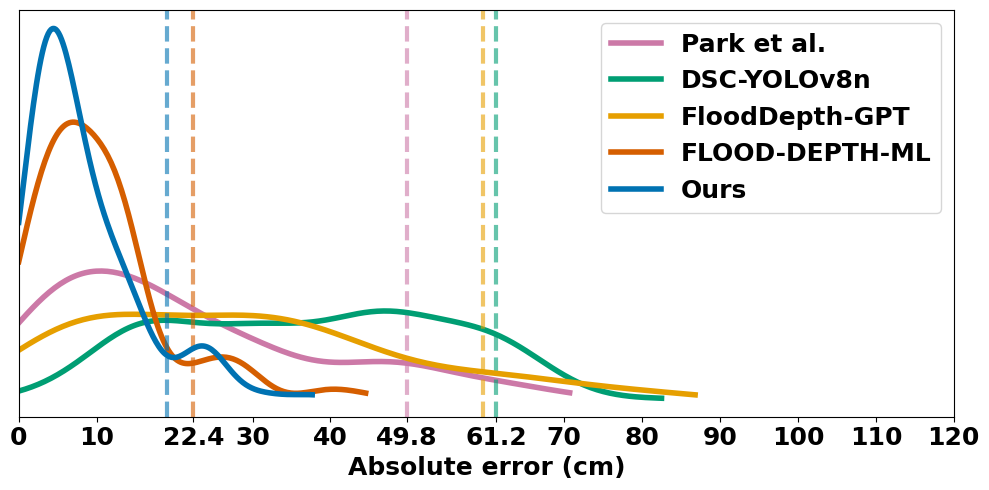

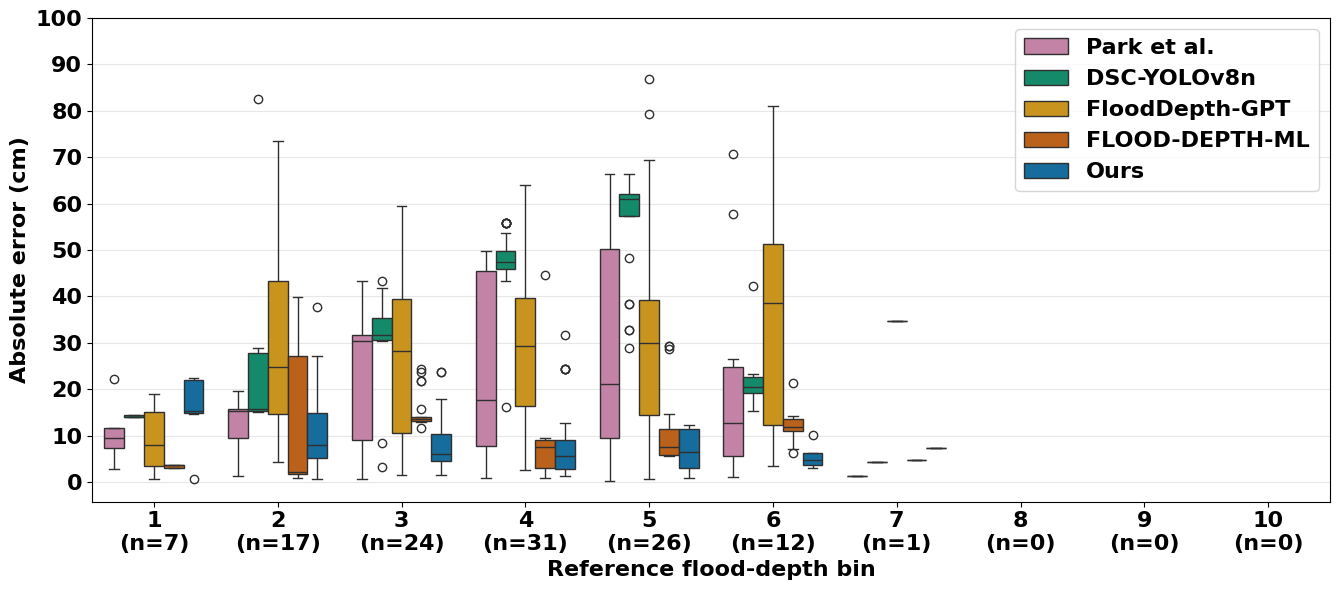

In [3]:
print("=====================\nPark images: Synthetic\n=====================\n")

methods = selected_methods
park_images_syn_results = build_comparison_subset(
    all_syn_results, methods, anchor_method=PARK
)


park_gts_syn, syn_park_images_results = evaluate_subset(
    park_images_syn_results, methods, "synthetic", "park"
)

fig_pdf = plot_mae_pdfs(park_gts_syn, syn_park_images_results, maxX=120, methods_color=methods_color)
fig_pdf.savefig(FIGURE_DIR / f"syn_park_images_pdf.pdf", format="pdf", bbox_inches="tight")


fig_box = plot_per_level_boxplot(park_images_syn_results, methods_color=methods_color)
fig_box.savefig(FIGURE_DIR / f"syn_park_images_box.pdf", format="pdf", bbox_inches="tight")

#### Real-world images

This comparison uses the common subset of real-world images for which all five methods return a valid numerical estimate. The current sample size is computed directly from the loaded results.


Park images: Real-world

FloodDepth-GPT: mae=21.45, std=14.16
park: mae=26.58, std=22.78
DSC-YOLOv8n: mae=30.52, std=20.61
FLOOD-DEPTH-ML: mae=10.76, std=8.75
20depths Wm=0.2: mae=10.99, std=11.25


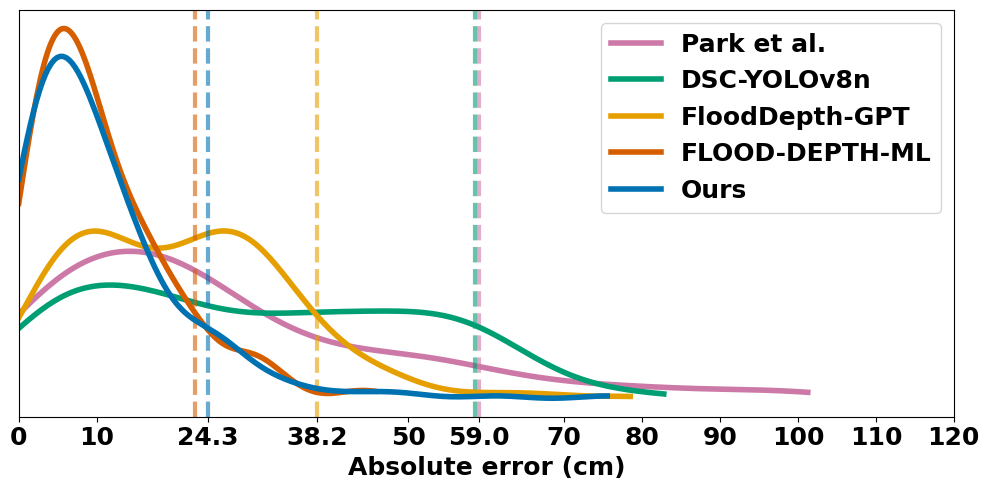

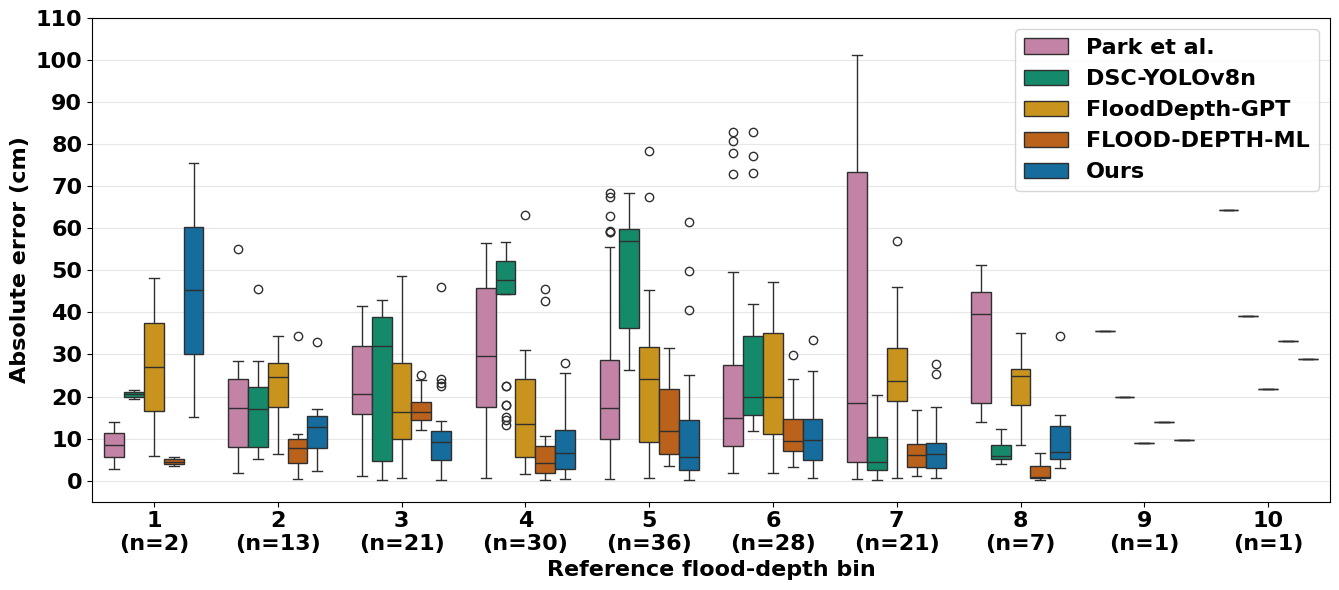

In [4]:
print("=====================\nPark images: Real-world\n=====================\n")

methods = selected_methods
park_images_real_results = build_comparison_subset(
    all_real_results, methods, anchor_method=PARK
)


park_gts_real, real_park_images_results = evaluate_subset(
    park_images_real_results, methods, "real world", "park"
)

fig_pdf = plot_mae_pdfs(park_gts_real, real_park_images_results, maxX=120, methods_color=methods_color)


fig_pdf.savefig(FIGURE_DIR / f"real_park_images_pdf.pdf", format="pdf", bbox_inches="tight")

fig_box = plot_per_level_boxplot(park_images_real_results, methods_color=methods_color)
fig_box.savefig(FIGURE_DIR / f"real_park_images_box.pdf", format="pdf", bbox_inches="tight")

## Analysis on the common Park-uncovered subset

This analysis uses images not covered by Park and keeps only those for which DSC-YOLOv8n, FloodDepth-GPT, FLOOD-DEPTH-ML, and Ours all return finite estimates. This is the paired Park-uncovered comparison reported in the paper; its sample size is computed from the current result files.


synthetic: common Park-uncovered N=67
  DSC-YOLOv8n: MAE ± STD=37.71 ± 26.23 cm
  FloodDepth-GPT: MAE ± STD=26.13 ± 17.94 cm
  FLOOD-DEPTH-ML: MAE ± STD=15.98 ± 16.27 cm
  Ours: MAE ± STD=10.57 ± 10.48 cm


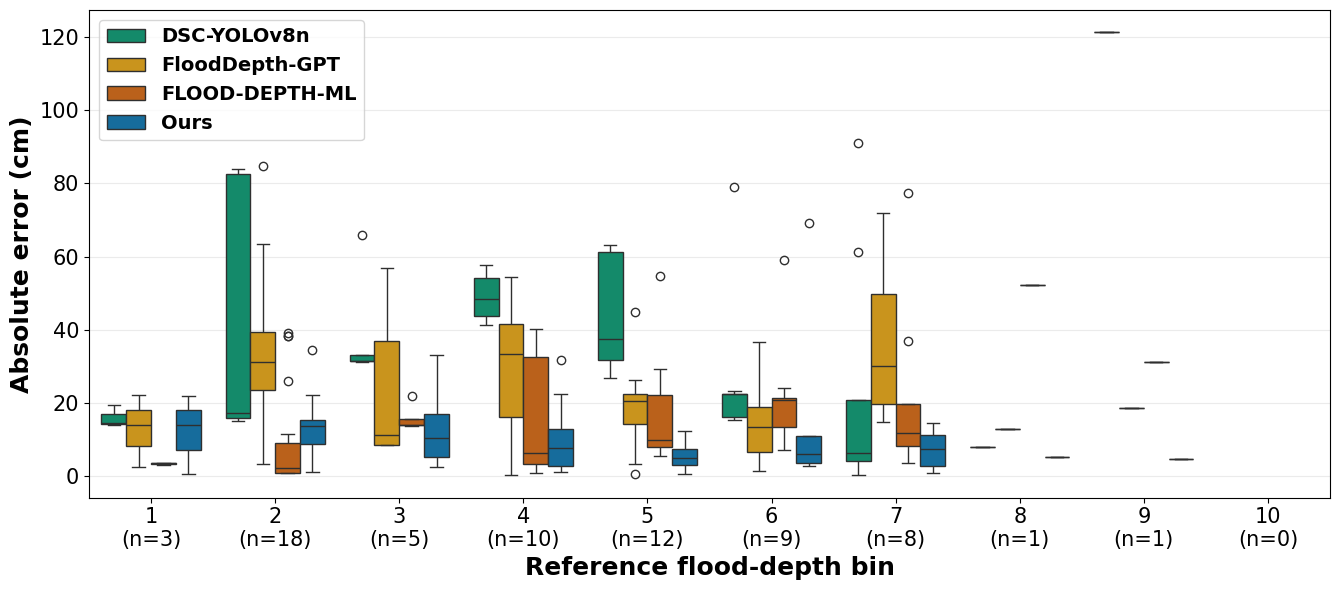

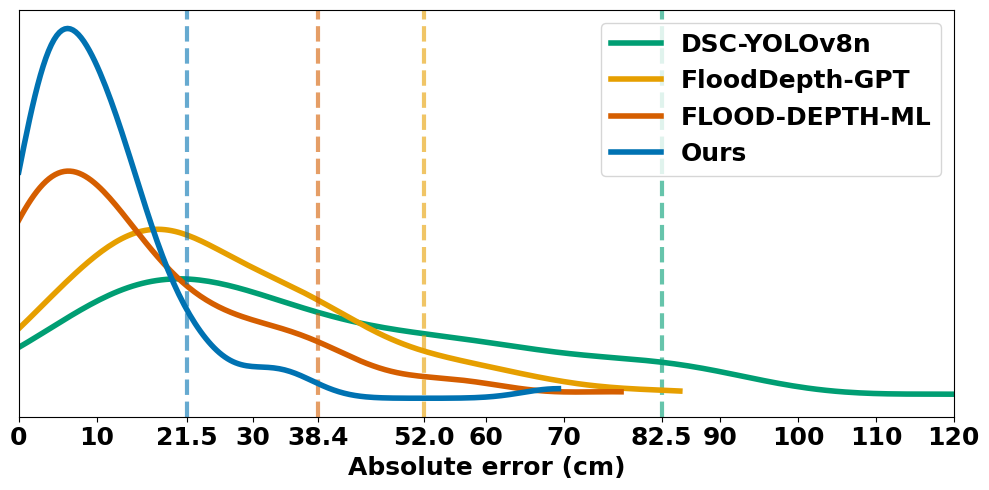

real world: common Park-uncovered N=39
  DSC-YOLOv8n: MAE ± STD=23.79 ± 18.35 cm
  FloodDepth-GPT: MAE ± STD=23.85 ± 14.76 cm
  FLOOD-DEPTH-ML: MAE ± STD=12.80 ± 9.41 cm
  Ours: MAE ± STD=10.60 ± 10.34 cm


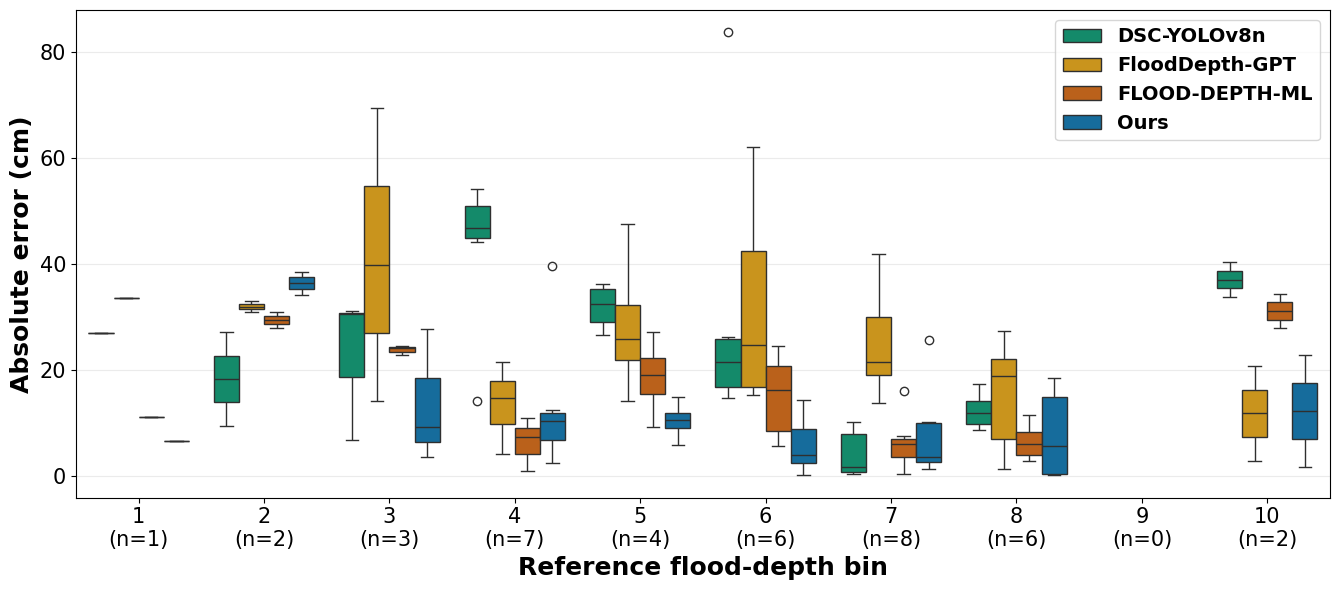

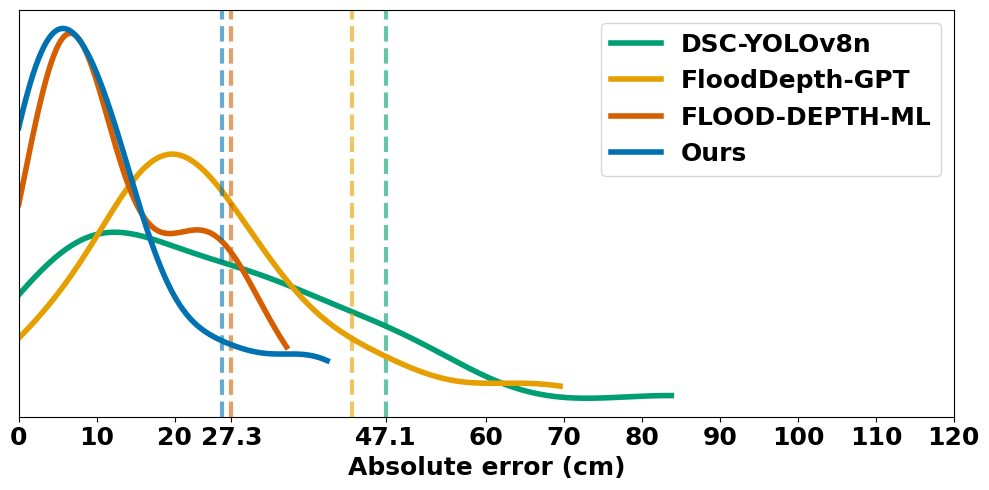

,Dataset,Method,Common N,MAE (cm),STD AE (cm),MAE ± STD (cm)
0,synthetic,DSC-YOLOv8n,67,37.7051,26.2344,37.71 ± 26.23
1,synthetic,FloodDepth-GPT,67,26.1269,17.9386,26.13 ± 17.94
2,synthetic,FLOOD-DEPTH-ML,67,15.9836,16.2716,15.98 ± 16.27
3,synthetic,Ours,67,10.5710,10.4832,10.57 ± 10.48
4,real world,DSC-YOLOv8n,39,23.7877,18.3450,23.79 ± 18.35
5,real world,FloodDepth-GPT,39,23.8523,14.7629,23.85 ± 14.76
6,real world,FLOOD-DEPTH-ML,39,12.8046,9.4123,12.80 ± 9.41
7,real world,Ours,39,10.6013,10.3381,10.60 ± 10.34


In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from analysis_utils import map_to_depth_interval


NON_PARK_METHODS = [DSC, GPT, FDML, OURS]
METHOD_LABELS = {
    DSC: "DSC-YOLOv8n",
    GPT: "FloodDepth-GPT",
    FDML: "FLOOD-DEPTH-ML",
    OURS: "Ours",
}


def build_park_uncovered_subset(all_results):
    """Return the fixed set of images for which Park has no valid estimate."""
    subset = {}
    for image_name, result in all_results.items():
        if PARK in result and np.isfinite(result[PARK]):
            continue

        selected = {"gt": result["gt"]}
        if "gt_level" in result:
            selected["gt_level"] = result["gt_level"]
        for method in NON_PARK_METHODS:
            if method in result and np.isfinite(result[method]):
                selected[method] = result[method]
        subset[image_name] = selected

    return dict(sorted(subset.items()))


def plot_common_park_uncovered_boxplot(
    target_results, valid_counts, show_legend_counts=True
):
    """Plot interval-wise errors, optionally showing total valid counts."""
    rows = []
    interval_counts = {}

    for result in target_results.values():
        interval = map_to_depth_interval(result["gt"])
        interval_counts[interval] = interval_counts.get(interval, 0) + 1
        for method in NON_PARK_METHODS:
            prediction = result.get(method, np.nan)
            if np.isfinite(prediction):
                rows.append({
                    "interval": interval,
                    "method": method,
                    "error": abs(prediction - result["gt"]),
                })

    dataframe = pd.DataFrame(rows)
    fig, ax = plt.subplots(figsize=(13.5, 6))
    sns.boxplot(
        data=dataframe,
        x="interval",
        y="error",
        hue="method",
        order=range(1, 11),
        hue_order=NON_PARK_METHODS,
        palette=methods_color,
        dodge=True,
        ax=ax,
    )

    labels = [
        f"{interval}\n(n={interval_counts.get(interval, 0)})"
        for interval in range(1, 11)
    ]
    ax.set_xticks(range(10))
    ax.set_xticklabels(labels)
    ax.set_xlabel("Reference flood-depth bin", fontsize=18, fontweight="bold")
    ax.set_ylabel("Absolute error (cm)", fontsize=18, fontweight="bold")
    ax.tick_params(axis="both", labelsize=15)

    handles, _ = ax.get_legend_handles_labels()
    if show_legend_counts:
        legend_labels = [
            f"{METHOD_LABELS[method]} (N={valid_counts[method]})"
            for method in NON_PARK_METHODS
        ]
    else:
        legend_labels = [
            METHOD_LABELS[method] for method in NON_PARK_METHODS
        ]
    ax.legend(
        handles,
        legend_labels,
        title=None,
        prop={"size": 14, "weight": "bold"},
    )
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()
    return fig

def build_common_park_uncovered_subset(target_results):
    """Keep images with finite predictions from all four methods."""
    common = {
        image_name: result
        for image_name, result in target_results.items()
        if all(
            method in result and np.isfinite(result[method])
            for method in NON_PARK_METHODS
        )
    }
    return dict(sorted(common.items()))


common_configs = [
    ("synthetic", build_park_uncovered_subset(all_syn_results), "syn"),
    ("real world", build_park_uncovered_subset(all_real_results), "real"),
]
common_metric_rows = []
common_park_uncovered_subsets = {}

for dataset, target_results, file_label in common_configs:
    common_results = build_common_park_uncovered_subset(target_results)
    common_park_uncovered_subsets[dataset] = common_results

    ground_truths = np.asarray([
        result["gt"] for result in common_results.values()
    ], dtype=float)
    method_estimations = {}
    valid_counts = {method: len(common_results) for method in NON_PARK_METHODS}

    print(
        f"{dataset}: common Park-uncovered N={len(common_results)}"
    )
    for method in NON_PARK_METHODS:
        predictions = np.asarray([
            result[method] for result in common_results.values()
        ], dtype=float)
        method_estimations[method] = predictions
        errors = np.abs(predictions - ground_truths)
        mae = np.mean(errors)
        std = np.std(errors, ddof=0)
        common_metric_rows.append({
            "Dataset": dataset,
            "Method": METHOD_LABELS[method],
            "Common N": len(common_results),
            "MAE (cm)": mae,
            "STD AE (cm)": std,
            "MAE ± STD (cm)": f"{mae:.2f} ± {std:.2f}",
        })
        print(
            f"  {METHOD_LABELS[method]}: "
            f"MAE ± STD={mae:.2f} ± {std:.2f} cm"
        )

    fig_box = plot_common_park_uncovered_boxplot(
        common_results, valid_counts, show_legend_counts=False
    )
    fig_box.savefig(
        FIGURE_DIR / f"{file_label}_common_park_uncovered_images_box.pdf",
        format="pdf",
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig_box)

    fig_pdf = plot_mae_pdfs(
        ground_truths,
        method_estimations,
        maxX=120,
        methods_color=methods_color,
    )
    fig_pdf.savefig(
        FIGURE_DIR / f"{file_label}_common_park_uncovered_images_pdf.pdf",
        format="pdf",
        bbox_inches="tight",
    )
    plt.close(fig_pdf)

common_park_uncovered_metrics_df = pd.DataFrame(common_metric_rows)
numeric_columns = common_park_uncovered_metrics_df.select_dtypes(
    include=[np.number]
).columns
common_park_uncovered_metrics_df[numeric_columns] = (
    common_park_uncovered_metrics_df[numeric_columns].round(4)
)
common_park_uncovered_metrics_df.to_csv(
    TABLE_DIR / "common_park_uncovered_mae_std.csv",
    index=False,
)
common_park_uncovered_metrics_df
